# Lecture 19, Regression downscaling

> A straight line that carries a large-scale climate signal down to one weather station

**The idea in everyday terms.** A climate model cannot tell us the temperature at one station, but it does simulate the large-scale air well: pressure, humidity, air temperature over a wide region. On warm, humid days the station is usually warm too. **Regression draws the best straight line through the points** of "large-scale value" against "station value". The **slope** of the line says how many degrees the station temperature changes when the large-scale value changes by one unit. Once we have the line, we put the climate model's future large-scale values into it and read off the future station temperature. This lecture follows Chapter 5 (Sections 5.1.1 and 5.1.2) of Lee and Singh (2019).

By the end of this lecture you should be able to:

- fit a straight line to a few points by hand and say whether its slope is clearly real;
- fit a line with several predictors at once;
- use the fitted line to downscale climate-model output;
- check the line on years that were not used to fit it, and explain why the downscaled series is too smooth.

All data are **synthetic**. The workbook `data/downscaling/lec19/lec19_worked_examples.xlsx` holds the same numbers: sheet `SimpleReg` is the hand example of Section 3, `MultiReg` and `CalVal` hold the later sections.

*What this means for hydrology:* a regression line is the cheapest way to turn a coarse climate-model field into a local number such as station temperature.

In [1]:
# Google Colab setup: install the packages this notebook uses.
# Runs only on Colab; skipped in Binder or a local Jupyter install.
import sys
if "google.colab" in sys.modules:
    %pip install -q numpy scipy pandas matplotlib

## Statistics words you need

Each word is used later, with a tiny number example.

- **Predictand** ($y$): the thing we want to know, here the station temperature. **Predictor** ($x$): the thing we use to estimate it, here a large-scale value.
- **Fitted value** ($\hat y$): what the line gives for a given $x$. **Residual** ($\varepsilon$): the miss, observed minus fitted. If the line gives 2.5 where $y=3$, the residual is 0.5.
- **Least squares:** the line is chosen so that the sum of the squared misses is as small as possible. That sum is $\mathrm{SSE}$.
- **$R^2$:** the share of the ups and downs of $y$ that the line explains, from 0 (none) to 1 (all).
- **Standard error:** how much the estimated slope would wobble if we had drawn another sample. Small is good.
- **$t$ value** ($T$): the slope divided by its standard error, "how many wobbles away from zero". **Degrees of freedom:** the number of points minus the number of numbers already estimated from them (two for a line).
- **Standardising:** subtracting the mean and dividing by the standard deviation, so every variable becomes a pure number around 0. A value of 1017.07 hPa with mean 1015.62 and standard deviation 2.87 becomes $(1017.07-1015.62)/2.87=0.50$.

## Notation

The symbols are those of Lee and Singh, Chapter 5; each is explained in words in the table. In the code a Greek letter is spelled out, a subscript follows an underscore, a hat is `_hat`, a bar is `_bar`, and the original (unstandardised) value carries `_org`.

| Book symbol | Meaning in words | Code and spreadsheet |
|:--|:--|:--|
| $y_i$ | predictand: January maximum temperature at the station, °C | `y`, `y_org` |
| $x_i$ | predictor; with several predictors $x_1,x_2,x_3$ = pressure (hPa), humidity (g/kg), air temperature (°C) | `x`, `x_1`, `x_2`, `x_3` |
| $\beta_0,\beta_1,\dots$ ; $\hat\beta$ | intercept and slopes of the line; the hat means "estimated from the data" | `beta_0_hat`, `beta_hat` |
| $\varepsilon_i$ | residual, observed minus fitted | `eps` |
| $n$, $S$ | number of years (points), number of predictors | `n`, `S` |
| $\mathrm{SSE}$ | sum of the squared residuals | `SSE` |
| $s_\varepsilon^2$, $s_{\hat\beta_1}^2$ | typical squared miss of the line; squared standard error of the slope | `s2_eps`, `s2_beta_1_hat` |
| $T$, $t_{\alpha/2,n-2}$ | $t$ value and the threshold it is compared with | `T`, `t_crit` |
| $\bar x,\bar y,s_x,s_y$ | mean and standard deviation | `x_bar`, `y_bar`, `s_x`, `s_y` |
| $x_i^{org}$, $x_i$ | predictor before and after standardising (same for $y$) | `x_org`, `x`; `y_org`, `y` |
| $\hat y_i$, $\hat y_i^{org}$ | fitted value (standardised) and in °C | `y_hat`, `y_hat_org` |
| $\mathbf X$, $\mathbf y$ | table of predictors (first column all ones) and the list of $y_i$ | `X`, `y` |

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

def read_csv(name):
    # Local copy of the repository first; on Colab fall back to the GitHub copy.
    path = f"data/downscaling/lec19/{name}"
    try:
        return pd.read_csv(path)
    except FileNotFoundError:
        return pd.read_csv("https://raw.githubusercontent.com/drvivekhydro/hydroclimatology/main/" + path)

obs = read_csv("lec19_reanalysis_obs.csv")   # 40 Januaries, 1961-2000: station y and reanalysis x_1, x_2, x_3
gcm = read_csv("lec19_gcm.csv")              # GCM predictors 1951-2100, in the GCM's own units
obs.head()

,year,slp_hPa,q_gkg,t_air_C,tmax_C
0,1961,1019.35,1.781,-7.38,-3.47
1,1962,1015.60,1.704,-11.12,-5.76
2,1963,1014.29,2.346,-11.77,-4.36
3,1964,1012.89,1.377,-10.26,-3.91
4,1965,1018.27,1.989,-15.31,-7.24


## 5.1 Linear regression based downscaling

Regression downscaling needs three data sets (Section 5.1):

1. observations of the variable of interest at the station, the **predictand** $y$;
2. **reanalysis** values of the **predictors** $x$ for the same years (a reanalysis is a record of the real large-scale weather, so each predictor value belongs to the same year as the observation);
3. the same predictors from the **climate model**, for a past (base) period and for the future.

The steps: **(1)** fit the line of $y$ on $x$ with the reanalysis; **(2)** put the climate-model predictors into the line instead; **(3)** read the future station value.

Our synthetic station is a January series: `tmax_C` is the January mean of the daily maximum temperature, and the predictors are sea-level pressure `slp_hPa` ($x_1$), specific humidity `q_gkg` ($x_2$) and near-surface air temperature `t_air_C` ($x_3$). Only January is used so that the seasons do not mix, as in the book.

*What this means for hydrology:* the observed series and the reanalysis must overlap in time, so the line can only be as good as the years we have.

### 5.1.1 Simple linear regression

**In words.** We have $n$ pairs of values $(x_i,y_i)$ and look for a straight line. The deterministic line is $y=\beta_0+\beta_1x$: $\beta_0$ is the value of $y$ at $x=0$ and $\beta_1$ is the **slope**, the change of $y$ when $x$ rises by one unit. Real points do not sit on a line, so the book adds a random noise $\varepsilon$ (Eq. 5.1), assumed normal with mean 0 and variance $\sigma_\varepsilon^2$:

$$Y=\beta_0+\beta_1X+\varepsilon .$$

$X$ is the predictor, $Y$ the predictand. For the sample, each point misses the line by $\varepsilon_i=y_i-(\beta_0+\beta_1x_i)$, and the **sum of squared errors** is (Eq. 5.2)

$$\mathrm{SSE}=\sum_{i=1}^{n}\bigl(y_i-(\beta_0+\beta_1x_i)\bigr)^2=\sum_{i=1}^{n}\varepsilon_i^2 .$$

Squaring stops misses above and below the line from cancelling. The **least-squares estimate** is the pair $(\beta_0,\beta_1)$ with the smallest SSE. At the bottom of the SSE "bowl" its slope in both directions is zero, so we set the derivatives to zero (Eqs. 5.3 and 5.4):

$$\frac{\partial\mathrm{SSE}}{\partial\beta_0}=-2\sum_i\bigl(y_i-(\beta_0+\beta_1x_i)\bigr)=0,\qquad
\frac{\partial\mathrm{SSE}}{\partial\beta_1}=-2\sum_i\bigl(y_i-(\beta_0+\beta_1x_i)\bigr)x_i=0 .$$

Solving the two equations gives the estimates, marked with a hat (Eqs. 5.5 and 5.6):

$$\hat\beta_1=\frac{\sum(x_i-\bar x)(y_i-\bar y)}{\sum(x_i-\bar x)^2},\qquad \hat\beta_0=\bar y-\hat\beta_1\bar x .$$

Gloss: the slope is "how much $x$ and $y$ move together" over "how much $x$ moves by itself", and the line passes through the point of means. The variance of the slope estimate is estimated by (Eq. 5.7), using the typical squared miss of Eq. 5.8:

$$s_{\hat\beta_1}^2=\frac{s_\varepsilon^2}{\sum(x_i-\bar x)^2},\qquad s_\varepsilon^2=\frac{\sum(y_i-\hat y_i)^2}{n-2}=\frac{\mathrm{SSE}}{n-2}.$$

The divisor $n-2$ is the **degrees of freedom**: $n$ points minus the two numbers ($\beta_0,\beta_1$) already estimated from them.

*What this means for hydrology:* the slope is the "exchange rate" between the large-scale predictor and the local variable.

#### 5.1.1.1 Significance test

**In words.** With few points a slope can appear by luck, so we ask: *is the slope clearly different from zero, or could it be luck?* The book standardises the slope estimate into (Eq. 5.9)

$$T=\frac{\hat\beta_1-\beta_1}{s_{\hat\beta_1}},$$

which follows a $t$ distribution with $n-2$ degrees of freedom. Test the **null hypothesis** $H_0:\beta_1=0$ (no relation) against $H_a:\beta_1\neq0$; under $H_0$, $T=\hat\beta_1/s_{\hat\beta_1}$, the slope measured in units of its own wobble. Compare it with the critical value $t_{\alpha/2,\,n-2}$: reject $H_0$ when $|T|\ge t_{\alpha/2,\,n-2}$. Then the predictor has a real relation with $y$, which is what downscaling needs. The **$p$-value** is the chance of seeing a $T$ this large if $H_0$ were true, $p=2[1-\Pr(T\le|t|)]$, from the same $t$ distribution. We use $\alpha=0.05$; with few points the critical value is larger than 1.96, so use the $t$ value.

*What this means for hydrology:* a predictor is only worth using if its slope is clearly real.

### Example 5.1 (by hand): simple regression, test, then projection

**Problem.** Six Januaries give a humidity predictor $x$ (g/kg) and a station maximum temperature $y$ (°C):

| $i$ | 1 | 2 | 3 | 4 | 5 | 6 |
|:--|--:|--:|--:|--:|--:|--:|
| $x_i$ | 1.5 | 1.8 | 2.1 | 2.4 | 2.7 | 3.0 |
| $y_i$ | −8.0 | −8.6 | −4.4 | −6.0 | −2.0 | −4.0 |

Fit the line $y=\hat\beta_0+\hat\beta_1x$, decide whether the slope is clearly real ($\alpha=0.05$), and predict $y$ for a climate-model value $x_0=2.0$ g/kg.

**Step 1, means** (the line passes through them). $\bar x=13.5/6=2.25$ and $\bar y=-33.0/6=-5.5$.

**Step 2, distances from the means** (the slope needs to know how $x$ and $y$ move together). $x_i-\bar x=-0.75,\,-0.45,\,-0.15,\,0.15,\,0.45,\,0.75$ and $y_i-\bar y=-2.5,\,-3.1,\,1.1,\,-0.5,\,3.5,\,1.5$.

**Step 3, sums** (the three building blocks of the formulas).

- $\sum(x_i-\bar x)^2=0.5625+0.2025+0.0225+0.0225+0.2025+0.5625=1.575$ (how much $x$ moves by itself)
- $\sum(x_i-\bar x)(y_i-\bar y)=1.875+1.395-0.165-0.075+1.575+1.125=5.730$ (how much they move together)
- $\sum(y_i-\bar y)^2=6.25+9.61+1.21+0.25+12.25+2.25=31.82$ (how much $y$ moves in total)

**Step 4, the line** (Eqs. 5.5 and 5.6). $\hat\beta_1=5.730/1.575=3.6381$ °C per g/kg, and $\hat\beta_0=-5.5-3.6381\times2.25=-5.5-8.1857=-13.6857$ °C.

**Step 5, the misses** (needed for SSE). Fitted values $\hat y_i=-13.6857+3.6381\,x_i$: $-8.2286,\,-7.1371,\,-6.0457,\,-4.9543,\,-3.8629,\,-2.7714$. Residuals $\varepsilon_i=y_i-\hat y_i$: $0.2286,\,-1.4629,\,1.6457,\,-1.0457,\,1.8629,\,-1.2286$ (they add to zero). Squared and added: $\mathrm{SSE}=0.0522+2.1400+2.7084+1.0935+3.4702+1.5094=10.9737$. (Any other line through the means has a larger SSE; the code below tries two.)

**Step 6, how much the slope wobbles** (Eqs. 5.8 and 5.7). $s_\varepsilon^2=10.9737/(6-2)=2.7434$; $s_{\hat\beta_1}^2=2.7434/1.575=1.7418$; standard error $s_{\hat\beta_1}=1.3198$.

**Step 7, is the slope clearly real?** (Eq. 5.9). $T=3.6381/1.3198=2.757$. The threshold for 4 degrees of freedom is $t_{0.025,4}=2.776$. Since $2.757<2.776$, the slope is not quite clearly different from zero ($p\approx0.051$).

**Step 8, how good, and a prediction.** $R^2=1-10.9737/31.82=0.655$: the line explains about two thirds of the ups and downs. At $x_0=2.0$: $\hat y_0=-13.6857+3.6381\times2.0=-6.41$ °C.

**Answer.** $\hat y=-13.686+3.638\,x$, $R^2=0.655$. In plain words: with only six years, we cannot be sure the positive slope is not luck (the familiar 1.96 would have said "sure", wrongly). The line predicts $-6.4$ °C for 2.0 g/kg.

*What this means for hydrology:* a short record can show a plausible relation that is still not statistically safe, so always run the test before downscaling.

In [3]:
x_h = np.array([1.5, 1.8, 2.1, 2.4, 2.7, 3.0])
y_h = np.array([-8.0, -8.6, -4.4, -6.0, -2.0, -4.0])
n_h = len(x_h)

x_bar, y_bar = x_h.mean(), y_h.mean()
S_xx = np.sum((x_h - x_bar)**2)
S_xy = np.sum((x_h - x_bar) * (y_h - y_bar))
S_yy = np.sum((y_h - y_bar)**2)
beta_1_hat = S_xy / S_xx                                  # Eq. 5.5
beta_0_hat = y_bar - beta_1_hat * x_bar                   # Eq. 5.6
y_hat = beta_0_hat + beta_1_hat * x_h
eps = y_h - y_hat
SSE = np.sum(eps**2)
s2_eps = SSE / (n_h - 2)                                  # Eq. 5.8
s_beta_1_hat = np.sqrt(s2_eps / S_xx)                     # Eq. 5.7
T = beta_1_hat / s_beta_1_hat                             # Eq. 5.9
t_crit = stats.t.ppf(1 - 0.05 / 2, n_h - 2)
p = 2 * stats.t.sf(abs(T), n_h - 2)

print(f"x_bar = {x_bar:.2f}, y_bar = {y_bar:.2f}, S_xx = {S_xx:.3f}, S_xy = {S_xy:.3f}, S_yy = {S_yy:.2f}")
print(f"beta_1_hat = {beta_1_hat:.4f}, beta_0_hat = {beta_0_hat:.4f}")
print("eps =", np.round(eps, 4), f" sum = {eps.sum():.1e}")
print(f"SSE = {SSE:.4f}, s_eps^2 = {s2_eps:.4f}, s_beta_1_hat = {s_beta_1_hat:.4f}")
print(f"T = {T:.3f}, t_crit = {t_crit:.3f}, p = {p:.3f} -> {'reject' if abs(T) >= t_crit else 'do not reject'} H0 (1.96 would have rejected)")
print(f"R^2 = {1 - SSE / S_yy:.3f}, y_hat at x_0 = 2.0: {beta_0_hat + beta_1_hat * 2.0:.2f} C")
for trial in (3.0, 4.5):   # other lines through the means: SSE must be larger
    e_t = y_h - (y_bar + trial * (x_h - x_bar))
    print(f"line through the means with slope {trial}: SSE = {np.sum(e_t**2):.3f} (larger than {SSE:.3f})")
print("check with scipy.stats.linregress:", np.round(stats.linregress(x_h, y_h)[:2], 4))
print("sheet SimpleReg: beta_1_hat N9, beta_0_hat N10, SSE N11, T N15, t_crit N17, p N18, R^2 N21, y_hat_0 N23")

x_bar = 2.25, y_bar = -5.50, S_xx = 1.575, S_xy = 5.730, S_yy = 31.82
beta_1_hat = 3.6381, beta_0_hat = -13.6857
eps = [ 0.2286 -1.4629  1.6457 -1.0457  1.8629 -1.2286]  sum = 2.7e-15
SSE = 10.9737, s_eps^2 = 2.7434, s_beta_1_hat = 1.3198
T = 2.757, t_crit = 2.776, p = 0.051 -> do not reject H0 (1.96 would have rejected)
R^2 = 0.655, y_hat at x_0 = 2.0: -6.41 C
line through the means with slope 3.0: SSE = 11.615 (larger than 10.974)
line through the means with slope 4.5: SSE = 12.144 (larger than 10.974)
check with scipy.stats.linregress: [  3.6381 -13.6857]
sheet SimpleReg: beta_1_hat N9, beta_0_hat N10, SSE N11, T N15, t_crit N17, p N18, R^2 N21, y_hat_0 N23


n = 40: beta_0_hat = -11.03 C, beta_1_hat = 2.88 C per g/kg, s_beta_1_hat = 1.01
T = 2.86, t_crit = t(0.025, 38) = 2.024, p = 0.0068, R^2 = 0.18


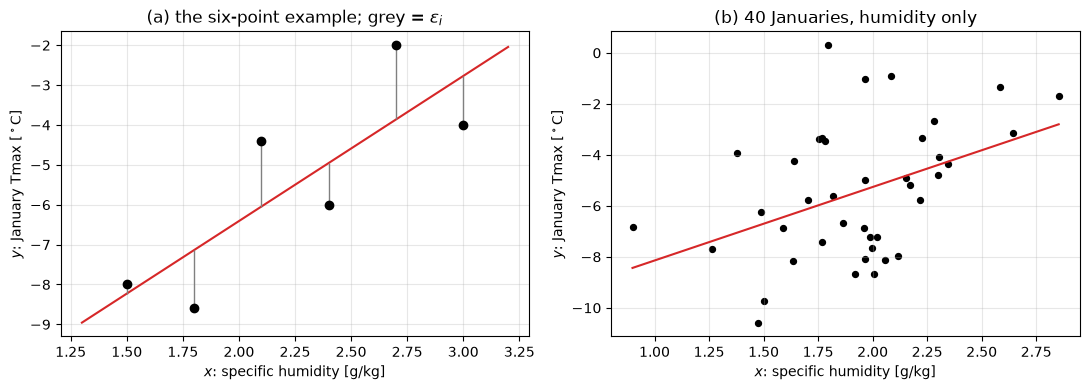

In [4]:
# Running example: 40 Januaries, humidity as the single predictor
x = obs.q_gkg.to_numpy();  y = obs.tmax_C.to_numpy();  n = len(x)
x_bar, y_bar = x.mean(), y.mean()
beta_1_hat = np.sum((x - x_bar) * (y - y_bar)) / np.sum((x - x_bar)**2)
beta_0_hat = y_bar - beta_1_hat * x_bar
eps = y - (beta_0_hat + beta_1_hat * x)
s2_eps = np.sum(eps**2) / (n - 2)
s_beta_1_hat = np.sqrt(s2_eps / np.sum((x - x_bar)**2))
T = beta_1_hat / s_beta_1_hat
t_crit = stats.t.ppf(1 - 0.05 / 2, n - 2)
print(f"n = {n}: beta_0_hat = {beta_0_hat:.2f} C, beta_1_hat = {beta_1_hat:.2f} C per g/kg, s_beta_1_hat = {s_beta_1_hat:.2f}")
print(f"T = {T:.2f}, t_crit = t(0.025, {n-2}) = {t_crit:.3f}, p = {2*stats.t.sf(abs(T), n-2):.4f}, R^2 = {1 - np.sum(eps**2)/np.sum((y-y_bar)**2):.2f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(x_h, y_h, color="k", zorder=3); xx = np.linspace(1.3, 3.2, 20)
ax[0].plot(xx, -13.6857 + 3.6381 * xx, "tab:red"); ax[0].vlines(x_h, y_h, y_hat, color="gray", lw=1)
ax[0].set_title("(a) the six-point example; grey = $\\varepsilon_i$")
ax[1].scatter(x, y, s=18, color="k"); xx = np.linspace(x.min(), x.max(), 20)
ax[1].plot(xx, beta_0_hat + beta_1_hat * xx, "tab:red"); ax[1].set_title("(b) 40 Januaries, humidity only")
for a in ax: a.set_xlabel("$x$: specific humidity [g/kg]"); a.set_ylabel("$y$: January Tmax [$^\\circ$C]")
fig.tight_layout()

### 5.1.2 Multiple linear regression

**In words.** Temperature at the station depends on pressure, humidity and air temperature together, so the line gets one slope per predictor (Eq. 5.10):

$$Y=\beta_0+\beta_1x_{i1}+\beta_2x_{i2}+\dots+\beta_Sx_{iS}+\varepsilon_i ,$$

with $S$ predictors. In matrix form (Eq. 5.11), $y_i=\boldsymbol\beta^\top\mathbf x_i+\varepsilon_i$, where $\mathbf x_i=[1,x_{i1},\dots,x_{iS}]^\top$ lists the predictors of year $i$ (with a leading 1 for the intercept) and $\boldsymbol\beta=[\beta_0,\dots,\beta_S]^\top$. Stacking the years, $\mathbf X$ is a table with $n$ rows and $S+1$ columns and $\mathbf y$ the list of observed values.

The sum of squared residuals is written and expanded as in the simple case:

$$\mathrm{SSE}=\boldsymbol\varepsilon^\top\boldsymbol\varepsilon=(\mathbf y-\mathbf X\boldsymbol\beta)^\top(\mathbf y-\mathbf X\boldsymbol\beta)=\mathbf y^\top\mathbf y-2\boldsymbol\beta^\top\mathbf X^\top\mathbf y+\boldsymbol\beta^\top\mathbf X^\top\mathbf X\boldsymbol\beta .$$

Setting its derivative to zero, $d\,\mathrm{SSE}/d\boldsymbol\beta=-2\mathbf X^\top\mathbf y+2\mathbf X^\top\mathbf X\boldsymbol\beta=\mathbf 0$, gives the least-squares estimator (Eq. 5.12) and the error variance (Eq. 5.13):

$$\hat{\boldsymbol\beta}=(\mathbf X^\top\mathbf X)^{-1}\mathbf X^\top\mathbf y,\qquad \hat\sigma_\varepsilon^2=\frac{\mathrm{SSE}}{n-S-1}.$$

Gloss: same idea as before, just with a table instead of single numbers; the divisor is the $n$ points minus the $S+1$ estimated numbers. For $S=1$ it reproduces Example 5.1. The $t$ test is applied to each slope with $n-S-1$ degrees of freedom.

### Example 5.2: several predictors, standardised

**a. Standardise.** The predictors are on very different scales (hPa against g/kg), and a variable with large numbers would dominate. So each variable, $y$ included, is standardised (Eq. 5.14), $x_i=(x_i^{org}-\bar x)/s_x$: subtract the mean, divide by the standard deviation.

**b. Fit and estimate.** The model is fitted to the standardised data with Eq. 5.12; all means are zero, so $\hat\beta_0=0$. The estimate is $\hat y_i=\hat{\boldsymbol\beta}^\top\mathbf x_i$ (Eq. 5.15).

**c. Back-standardise.** $\hat y_i^{org}=\hat y_i\,s_y+\bar y$ turns the estimate back into °C.

*What this means for hydrology:* several predictors usually explain more of the local weather than one, and each slope has its own test, so useless predictors can be spotted.

                beta_hat  s_beta       T       p
beta_0            0.0000  0.1040  0.0000  1.0000
beta_1 (SLP)      0.0704  0.1059  0.6648  0.5104
beta_2 (q)        0.2357  0.1096  2.1500  0.0384
beta_3 (T_air)    0.6654  0.1102  6.0383  0.0000
t_crit = t(0.025, 36) = 2.028   R^2 = 0.600   s_eps = 1.71 C
sheet MultiReg: beta_hat N10:N13, R^2 L22, s_eps^2 L19, coefficient table L27:P31


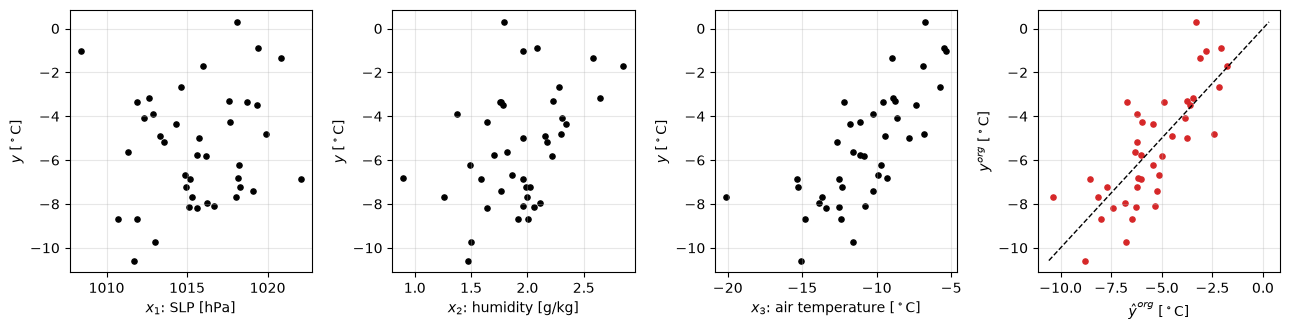

In [5]:
x_org = obs[["slp_hPa", "q_gkg", "t_air_C"]].to_numpy()
y_org = obs.tmax_C.to_numpy()
n, S = x_org.shape
x_bar, s_x = x_org.mean(axis=0), x_org.std(axis=0, ddof=1)
y_bar, s_y = y_org.mean(), y_org.std(ddof=1)

x = (x_org - x_bar) / s_x                                  # Eq. 5.14
y = (y_org - y_bar) / s_y
X = np.column_stack([np.ones(n), x])                       # n x (S+1)
XtX_inv = np.linalg.inv(X.T @ X)
beta_hat = XtX_inv @ X.T @ y                               # Eq. 5.12
y_hat = X @ beta_hat                                       # Eq. 5.15
eps = y - y_hat
SSE = np.sum(eps**2)
s2_eps = SSE / (n - S - 1)                                 # Eq. 5.13 (corrected divisor)
s_beta = np.sqrt(s2_eps * np.diag(XtX_inv))
T = beta_hat / s_beta
p = 2 * stats.t.sf(np.abs(T), n - S - 1)
t_crit = stats.t.ppf(1 - 0.05 / 2, n - S - 1)
R2 = 1 - SSE / np.sum((y - y.mean())**2)
y_hat_org = y_hat * s_y + y_bar                            # back-standardise

print((pd.DataFrame({"beta_hat": beta_hat, "s_beta": s_beta, "T": T, "p": p},
                    index=["beta_0", "beta_1 (SLP)", "beta_2 (q)", "beta_3 (T_air)"]).round(4) + 0.0).to_string())
print(f"t_crit = t(0.025, {n-S-1}) = {t_crit:.3f}   R^2 = {R2:.3f}   s_eps = {np.sqrt(s2_eps) * s_y:.2f} C")
print("sheet MultiReg: beta_hat N10:N13, R^2 L22, s_eps^2 L19, coefficient table L27:P31")

fig, ax = plt.subplots(1, 4, figsize=(13, 3.4))
for j, (a, nm) in enumerate(zip(ax[:3], ["SLP [hPa]", "humidity [g/kg]", "air temperature [$^\\circ$C]"])):
    a.scatter(x_org[:, j], y_org, s=14, color="k"); a.set_xlabel(f"$x_{j+1}$: {nm}"); a.set_ylabel("$y$ [$^\\circ$C]")
ax[3].scatter(y_hat_org, y_org, s=14, color="tab:red"); lim = [y_org.min(), y_org.max()]
ax[3].plot(lim, lim, "k--", lw=1); ax[3].set_xlabel("$\\hat y^{org}$ [$^\\circ$C]"); ax[3].set_ylabel("$y^{org}$ [$^\\circ$C]")
fig.tight_layout()

### Example 5.2 (continued): the climate-model predictors

In the fit above, humidity and air temperature are clearly real (their $|T|$ is above the threshold 2.03) and sea-level pressure is not ($p=0.51$). $R^2=0.60$ (the share of the ups and downs of $y$ explained), compared with 0.18 for humidity alone.

**d. Apply to the climate-model (GCM) predictors.** Three practical rules:

1. The model file has its own units (Pa, g/g, K), so convert to the reanalysis units first.
2. Standardise the model predictors with the mean and standard deviation of the **model's own base period** (1951 to 2005), for the base **and** the future. Do not use the future's own mean: that would erase the very warming we want to see.
3. Convert the result back to °C with the mean and standard deviation of the **observed** $y$.

*What this means for hydrology:* the base-period standardising also removes the climate model's constant bias, such as a station that is too cold in the model.

GCM base-period means (SLP hPa, q g/kg, T_air C): [1016.896    1.816   -7.901]  reanalysis: [1015.636    1.931  -10.776]
mean y_hat_org: base 1951-2005 = -5.46 C, 2071-2100 = -1.24 C, change = 4.22 C
sheet MultiReg: Z8, Z9, Z10


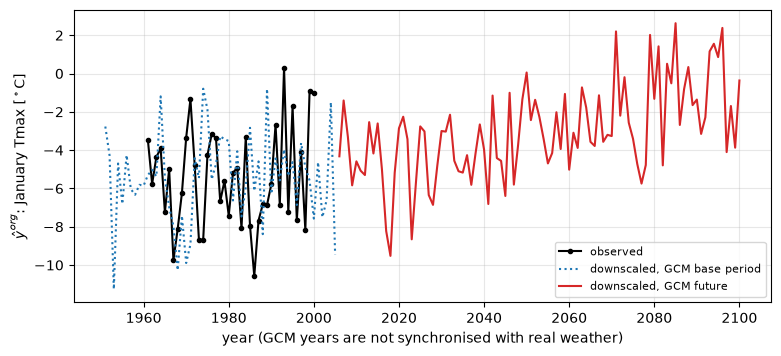

In [6]:
# convert GCM units to the reanalysis units: Pa -> hPa, g/g -> g/kg, K -> deg C
x_org_g = np.column_stack([gcm.slp_Pa / 100, gcm.q_gg * 1000, gcm.t_air_K - 273.15])
base = (gcm.year <= 2005).to_numpy()
x_bar_g, s_x_g = x_org_g[base].mean(axis=0), x_org_g[base].std(axis=0, ddof=1)     # base-period statistics only
x_g = (x_org_g - x_bar_g) / s_x_g                                                   # same for base and future
y_hat_g = np.column_stack([np.ones(len(gcm)), x_g]) @ beta_hat
y_hat_org_g = y_hat_g * s_y + y_bar                                                 # observed y_bar and s_y

fut = (gcm.year >= 2071).to_numpy()
print("GCM base-period means (SLP hPa, q g/kg, T_air C):", np.round(x_bar_g, 3), " reanalysis:", np.round(x_bar, 3))
print(f"mean y_hat_org: base 1951-2005 = {y_hat_org_g[base].mean():.2f} C, 2071-2100 = {y_hat_org_g[fut].mean():.2f} C, "
      f"change = {y_hat_org_g[fut].mean() - y_hat_org_g[base].mean():.2f} C")
print("sheet MultiReg: Z8, Z9, Z10")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(obs.year, y_org, "k-o", ms=3, label="observed")
ax.plot(gcm.year[gcm.year <= 2005], y_hat_org_g[gcm.year <= 2005], ":", color="tab:blue", label="downscaled, GCM base period")
ax.plot(gcm.year[gcm.year > 2005], y_hat_org_g[gcm.year > 2005], "-", color="tab:red", label="downscaled, GCM future")
ax.set_xlabel("year (GCM years are not synchronised with real weather)"); ax.set_ylabel("$\\hat y^{org}$: January Tmax [$^\\circ$C]"); ax.legend(fontsize=8)

The downscaled January maximum temperature rises steadily after 2005. The rise comes from the warming of the model's air temperature $x_3$ (and a little from humidity), which is why the predictor set must contain a variable that carries the climate signal.

*What this means for hydrology:* the projected warming is only as trustworthy as the assumption that the line fitted to 1961 to 2000 still holds in a warmer climate.

### Example 5.3 and Section 5.4: variance deflation, and a check on independent years

A line should be tested on years it has not seen. We fit with 1961 to 1990 and test on 1991 to 2000 (standardising with the 1961 to 1990 statistics only). Four numbers compare the two periods: the **bias** (average miss, positive means too warm), the **RMSE** (typical size of a miss, in °C), $R^2$, and the **SD ratio** (the standard deviation of the downscaled series divided by that of the observations).

**Why the downscaled series is too smooth.** The line only gives the part of $y$ that the predictors explain; the unexplained part (the residual) is left out. So the downscaled series varies less than the real one: its standard deviation is $\sqrt{R^2}$ times the observed one. The book shows this for rainfall, where $R^2$ is low and the effect is large.

                       bias [C]  RMSE [C]    R^2  SD ratio
calibration 1961-1990     0.000     1.558  0.488     0.699
validation 1991-2000     -1.097     1.900  0.756     0.987
sqrt(R^2) in calibration = 0.699  (equals the SD ratio)
sheet CalVal: skill measures W5:X8


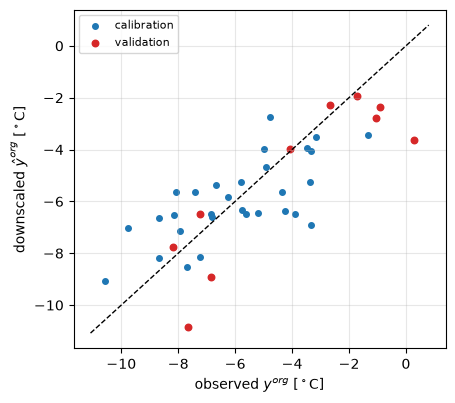

In [7]:
cal = (obs.year <= 1990).to_numpy();  val = ~cal

def fit_period(rows):
    xo, yo = x_org[rows], y_org[rows]
    mu, sd, ym, ys = xo.mean(axis=0), xo.std(axis=0, ddof=1), yo.mean(), yo.std(ddof=1)
    Xc = np.column_stack([np.ones(rows.sum()), (xo - mu) / sd])
    b = np.linalg.inv(Xc.T @ Xc) @ Xc.T @ ((yo - ym) / ys)
    return lambda xo_new: np.column_stack([np.ones(len(xo_new)), (xo_new - mu) / sd]) @ b * ys + ym

predict = fit_period(cal)                       # statistics and coefficients from 1961-1990 only
y_hat_org_all = predict(x_org)

rows = {}
for name, r in (("calibration 1961-1990", cal), ("validation 1991-2000", val)):
    e = y_hat_org_all[r] - y_org[r]
    rows[name] = {"bias [C]": e.mean(), "RMSE [C]": np.sqrt(np.mean(e**2)),
                  "R^2": np.corrcoef(y_hat_org_all[r], y_org[r])[0, 1]**2,
                  "SD ratio": y_hat_org_all[r].std(ddof=1) / y_org[r].std(ddof=1)}
tab = pd.DataFrame(rows).T
print(tab.round(3).to_string())
print(f"sqrt(R^2) in calibration = {np.sqrt(tab.loc['calibration 1961-1990', 'R^2']):.3f}  (equals the SD ratio)")
print("sheet CalVal: skill measures W5:X8")

fig, ax = plt.subplots(figsize=(4.8, 4.4))
ax.scatter(y_org[cal], y_hat_org_all[cal], s=16, color="tab:blue", label="calibration")
ax.scatter(y_org[val], y_hat_org_all[val], s=22, color="tab:red", label="validation")
lim = [y_org.min() - 0.5, y_org.max() + 0.5]; ax.plot(lim, lim, "k--", lw=1)
ax.set_xlabel("observed $y^{org}$ [$^\\circ$C]"); ax.set_ylabel("downscaled $\\hat y^{org}$ [$^\\circ$C]"); ax.legend(fontsize=8)

In calibration the SD ratio equals $\sqrt{R^2}$ (0.70), as stated. The validation numbers come from only ten years and are noisy: the bias is about $-1.1$ °C and the RMSE is somewhat larger than in calibration. A good test on past years does not prove that the line holds in a much warmer future. Where the variability matters (floods, droughts), Lecture 21 introduces weather generators.

*What this means for hydrology:* a downscaled series gives the average behaviour well but understates the extremes, which are what floods and heat waves are made of.

## Summary

- Regression draws the best straight line through predictor and station values; the slope says how much the station changes per unit of the predictor.
- Least squares picks the line with the smallest sum of squared misses (SSE); the $t$ test asks whether the slope is clearly different from zero, using the $t$ threshold, not 1.96.
- With several predictors the line has one slope each; standardise all variables first.
- For the climate model: convert units, standardise with the model's base-period mean and standard deviation, convert back with the observed mean and standard deviation.
- Test on years not used for the fit. The downscaled series is too smooth, with spread $\sqrt{R^2}$ times the observed.

## Check your understanding

1. In the hand example, $T=2.757$ and the threshold is 2.776. What do you conclude about the slope, and what would the value 1.96 have wrongly suggested?
2. Why do we standardise the predictors before fitting several of them at once?
3. Why must the future climate-model predictors be standardised with the base-period mean and standard deviation rather than their own?

## Try it yourself

- Remove $x_1$ (sea-level pressure) from the several-predictor fit and see how $R^2$ changes.
- Change `x_0` in the sheet `SimpleReg` to 4.0 g/kg (outside the data) and compare it with the range of the data.
- Fit on 1961 to 1980 and test on 1981 to 2000 in Section 6, and see which of the four numbers changes most.

```{note} Where this lecture differs from the book
- Eq. 5.13 prints the divisor as $n-k+1$ ($k$ is not defined); the correct divisor is $n-S-1$, used here.
- The rejection region in Section 5.1.1.1 is printed as $T\ge t_{\alpha/2,n-2}$; for a two-sided test it is $|T|\ge t_{\alpha/2,n-2}$.
- The book calls $Y$ "a predictand (or an explanatory variable)"; here the explanatory variable is the predictor $X$, as is usual.
- Example 5.2 writes "predictor" for the standardised predictand $y_i$; here it is the predictand.
- The six-point example, the 40 Januaries and the GCM series are synthetic and are not the book's data.
```

```{note} Sources
Written for **CE524 Applied Hydroclimatology**. The method and notation follow Lee, T., & Singh, V. P. (2019), *Statistical Downscaling for Hydrological and Environmental Applications*, CRC Press, Chapter 5, Sections 5.1.1 (simple linear regression and significance test) and 5.1.2 (multiple linear regression, standardisation), with Section 5.4 for context. The explanations, the synthetic data, the code and the figures are original. The perfect-prognosis setting is discussed in Lecture 16.

**All data are synthetic**: files `data/downscaling/lec19/lec19_reanalysis_obs.csv` and `lec19_gcm.csv`. The workbook `lec19_worked_examples.xlsx` reproduces the numbers of Sections 3, 4, 5 and 6 with live formulas.
```